In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets, svm
from sklearn.model_selection import train_test_split
from itertools import combinations

pd.set_option("display.expand_frame_repr", False)

In [2]:
iris = datasets.load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
df = pd.DataFrame(X, columns=iris.feature_names)
corr = df.corr()

best_pair = min(combinations(range(4), 2), key=lambda p: abs(corr.iloc[p[0], p[1]]))

print("Наименее коррелированные:", best_pair, iris.feature_names[best_pair[0]], "и", iris.feature_names[best_pair[1]])

# 4 признака
corr

Наименее коррелированные: (0, 1) sepal length (cm) и sepal width (cm)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [4]:
# 4 признака, all-vs-all (one-vs-one)
clf = svm.SVC(kernel="linear", decision_function_shape="ovo", C=10)
clf.fit(X_train, y_train)

print("coef_ shape:", clf.coef_.shape) # (n_classes * (n_classes — 1) / 2, n_features) 
print("intercept_ shape:", clf.intercept_.shape) # (n_classes * (n_classes — 1) / 2,)

# Выбираем 2 признака с наименьшей корреляцией из всех обучающий данных
X2_train = X_train[:, best_pair]
X2_test = X_test[:, best_pair]

clf2 = svm.SVC(kernel="linear", decision_function_shape="ovo", C=10)
clf2.fit(X2_train, y_train)
print(f"coef_: {clf2.coef_.shape}\n{clf2.coef_}")
print(f"intercept_:{clf2.intercept_.shape}\n{clf2.intercept_}")

coef_ shape: (3, 4)
intercept_ shape: (3,)
coef_: (3, 2)
[[-3.9655159   3.58621026]
 [-2.92649271  2.43831832]
 [-1.33393598 -1.33251707]]
intercept_:(3,)
[10.25859557  8.56125046 12.33471385]


In [ ]:
# Отберём по 2 тестовых примера каждого класса
idx_sel = []

for c in range(3):
    idx_sel += list(np.where(y_test == c)[0][:2])

idx_sel = idx_sel[:6]

X6 = X_test[idx_sel]
y6 = y_test[idx_sel]

# Матрица решающих функций OVO (n_samples, 3)
dec = clf.decision_function(X6)

pairs = [(0,1), (0,2), (1,2)] # порядок строк coef_ для ovo
votes_matrix = np.zeros((6, 3), dtype=int)
scores = np.zeros((6, 3))

for k, (i, j) in enumerate(pairs):
    a = dec[:, k]
    
    for s in range(6):
        if a[s] > 0:
            votes_matrix[s, i] += 1
            scores[s, i] += a[s]
        else:
            votes_matrix[s, j] += 1
            scores[s, j] -= a[s]

#pred_manual = np.array([np.argmax(scores[s]) for s in range(6)])

# sklearn: сначала по голосам, при равенстве — по сумме
pred_manual = np.array([
    np.argmax(votes_matrix[s]) if votes_matrix[s].max() >
    np.sort(votes_matrix[s])[-2] else np.argmax(scores[s])
    for s in range(6)
])

pd.DataFrame({
    "настоящее значение": y6,
    "a01": dec[:,0].round(2),
    "a02": dec[:,1].round(2),
    "a12": dec[:,2].round(2),
    "голоса_0": votes_matrix[:,0],
    "голоса_1": votes_matrix[:,1],
    "голоса_2": votes_matrix[:,2],
    "предсказание": pred_manual,
    "predict()": np.array(clf.predict(X6), dtype=int),
})

[[ 1.02948713  1.02903978 17.83014999]
 [ 1.65596331  1.29541789 20.37255484]
 [-2.69848353 -0.83030217  1.87129524]
 [-2.67392498 -0.84346992  1.60786909]
 [-4.61105998 -1.85204036 -5.2818164 ]
 [-3.20094945 -1.08621185 -0.06136324]]


,настоящее значение,a01,a02,a12,голоса_0,голоса_1,голоса_2,предсказание,predict()
0,0,1.03,1.03,17.83,2,1,0,0,0
1,0,1.66,1.30,20.37,2,1,0,0,0
2,1,-2.70,-0.83,1.87,0,2,1,1,1
3,1,-2.67,-0.84,1.61,0,2,1,1,1
4,2,-4.61,-1.85,-5.28,0,1,2,2,2
5,2,-3.20,-1.09,-0.06,0,1,2,2,2


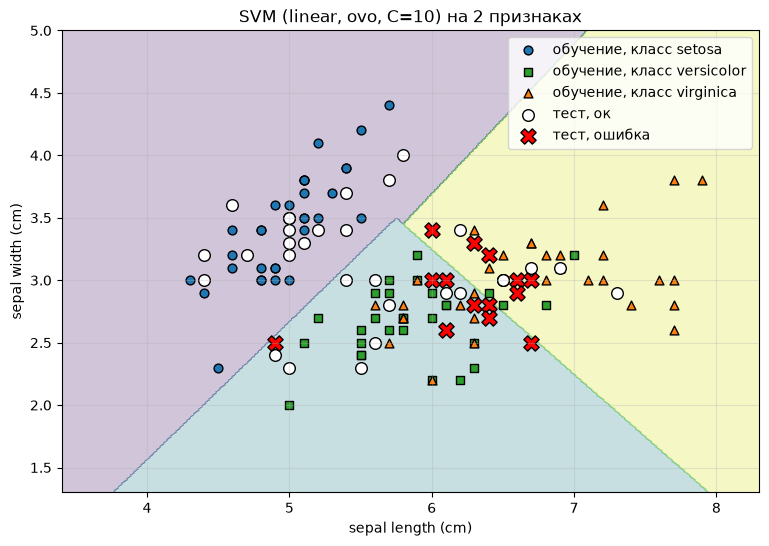

In [6]:
# Сетка для фона решающих областей
x_min, x_max = X2_test[:,0].min()-1, X2_test[:,0].max()+1
y_min, y_max = X2_test[:,1].min()-1, X2_test[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
Z = clf2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9,6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

# Обучающие точки
for c, marker, col in zip(range(3), "os^", ["tab:blue","tab:green","tab:orange"]):
    m = y_train == c
    plt.scatter(X2_train[m,0], X2_train[m,1], c=col, marker=marker, s=40, edgecolor="k", label=f"обучение, класс {iris.target_names[c]}")

# Тестовые точки
y_pred_all = clf2.predict(X2_test)
correct = y_pred_all == y_test
plt.scatter(X2_test[correct, 0], X2_test[correct, 1], c="white", edgecolor="k", s=70, marker="o", label="тест, ок")
plt.scatter(X2_test[~correct,0], X2_test[~correct,1], c="red", edgecolor="k", s=120, marker="X", label="тест, ошибка")

plt.xlabel(iris.feature_names[best_pair[0]])
plt.ylabel(iris.feature_names[best_pair[1]])
plt.title("SVM (linear, ovo, C=10) на 2 признаках")
plt.legend(); plt.grid(alpha=0.3); plt.show()